# Linear Regression with Gradient Descent (1D)

**Contents**
1. Data
2. Model and loss
3. Gradients
4. Gradient descent
5. Putting it together

Cells marked **Example** can simply be run. Cells marked **Exercise** contain `# TODO` gaps for you to complete.

## 0. Setup

In [3]:
!pip install numpy
!pip install matplotlib

  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 18.9 MB/s  0:00:00m0:00:0100:01
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.9/2.9 MB 27.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.7/4.7 MB 24.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8/8 [matplotlib]8 [matplotlib]


In [4]:
import numpy as np
import matplotlib.pyplot as plt

---
## 1. Data

### Example 1.1: Create a dataset

$$y = 2x + 1 + \varepsilon, \qquad \varepsilon \sim \mathcal{N}(0, 0.3^2)$$

In [5]:
rng = np.random.default_rng(seed=0)
n = 100

x = rng.uniform(0, 2, n)
y = 2 * x + 1 + rng.normal(0, 0.3, n)

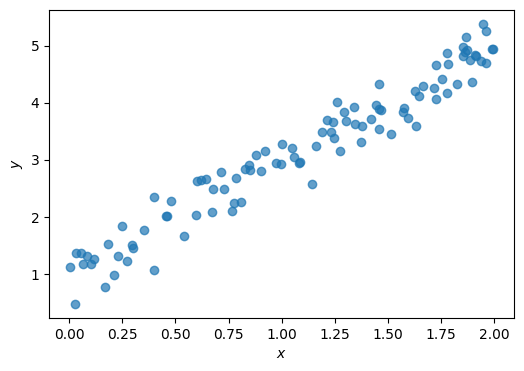

In [6]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(x, y, alpha=0.7)
ax.set_xlabel("$x$")
ax.set_ylabel("$y$")
plt.show()

---
## 2. Model and Loss

### Example 2.1: Prediction and mean squared error

Linear model to make predictions, measure how well it's doing with the mean squared error cost function

$$\hat{y} = wx + b \qquad\qquad J(w, b) = \frac{1}{2m}\sum_{i=1}^{m} (\hat{y}_i - y_i)^2$$

In [7]:
def predict(x, w, b):
    """Return predictions of the model y_hat = w * x + b."""
    return w * x + b


def mse(y_true, y_pred):
    """Return the mean squared error."""
    return (1/2) * np.mean((y_pred - y_true) ** 2)

### Make an initial guess of the parameters and plot the model prediction on top of the data

Loss/cost: 3.880141998771417


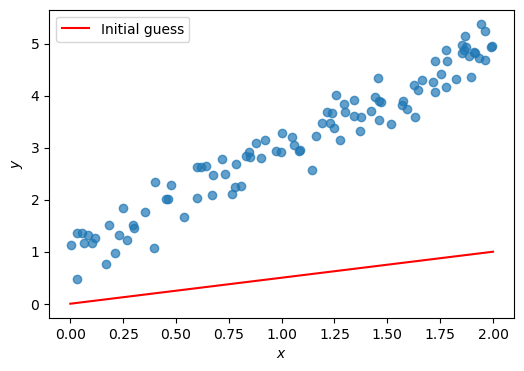

In [ ]:
w_guess, b_guess = 0.5, 0.0

print("Loss/cost:", mse(y, predict(x, w_guess, b_guess)))

x_line = np.linspace(0, 2, 100)

fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(x, y, alpha=0.7)
ax.plot(x_line, predict(x_line, w_guess, b_guess), color="red", label="Initial guess")
ax.set_xlabel("$x$")
ax.set_ylabel("$y$")
ax.legend()
plt.show()

### Exercise 1: The loss/cost curve

Fix $b = 1$ and plot the cost function $J(w, 1)$ for values of $w$ between $-1$ and $5$.
Where is the minimum?

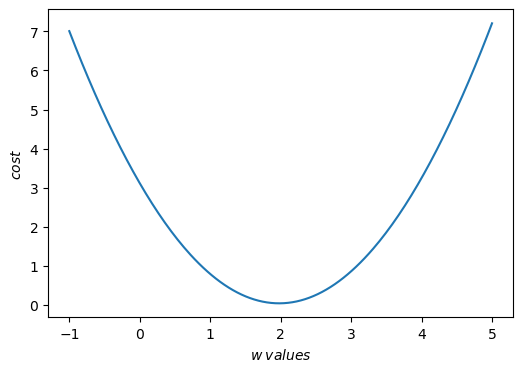

In [ ]:
w_values = np.linspace(-1, 5, 200)
costs = []

for w in w_values:
    # TODO: compute the cost for this w (with b = 1) and append it to costs
    predictions = predict(x,w,1)
    cost = mse(y, predictions)
    costs.append(cost)

# TODO: plot costs against w_values, with axis labels

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(w_values,costs)
ax.set_xlabel("$w_ values$")
ax.set_ylabel("$cost$")
plt.show()

---
## 3. Gradients

### Example 3.1: Gradients of the cost function

$$\frac{\partial J}{\partial w} = \frac{1}{m}\sum_{i=1}^{m} x_i\,(y_i - \hat{y}_i)
\qquad\qquad
\frac{\partial J}{\partial b} = \frac{1}{m}\sum_{i=1}^{m} (y_i - \hat{y}_i)$$

In [ ]:
def gradients(x, y, w, b):
    """Return the gradients (dJ/dw, dJ/db) of the MSE cost."""
    error = predict(x, w, b) - y
    dw = np.mean(x * error)
    db = np.mean(error)
    return dw, db

In [ ]:
dw, db = gradients(x, y, w_guess, b_guess)
print(f"dJ/dw = {dw:.4f}")
print(f"dJ/db = {db:.4f}")

dJ/dw = -3.4183
dJ/db = -2.6211


### Exercise 2: Checking gradients numerically

Check `gradients` using finite differences:

$$\frac{\partial J}{\partial w} \approx \frac{J(w + h, b) - J(w - h, b)}{2h}$$

In [ ]:
def numerical_gradients(x, y, w, b, h=1e-5):
    """Estimate (dJ/dw, dJ/db) using central finite differences."""
    # TODO: estimate dJ/dw
    dw = (mse(y, predict(x, w+h, b))- mse(y, predict(x, w-h, b)))/(2*h)

    # TODO: estimate dJ/db
    db = (mse(y, predict(x, w, b+h))- mse(y, predict(x, w, b-h)))/(2*h)

    return dw, db

In [ ]:
# Check your answer (should print True True)
analytic = gradients(x, y, w_guess, b_guess)
numeric = numerical_gradients(x, y, w_guess, b_guess)
print(np.isclose(analytic[0], numeric[0]), np.isclose(analytic[1], numeric[1]))

True True


---
## 4. Gradient Descent

### Example 4.1: The training loop

$$w \leftarrow w - \alpha\,\frac{\partial J}{\partial w} \qquad\qquad b \leftarrow b - \alpha\,\frac{\partial J}{\partial b}$$

In [ ]:
def gradient_descent(x, y, lr=0.1, n_iters=100, w=0.0, b=0.0):
    """Fit w and b by gradient descent. Returns w, b and the loss history."""
    history = []
    for _ in range(n_iters):
        dw, db = gradients(x, y, w, b)
        w = w - lr * dw
        b = b - lr * db
        history.append(mse(y, predict(x, w, b)))
    return w, b, history

In [ ]:
w_fit, b_fit, history = gradient_descent(x, y, lr=0.1, n_iters=100)

print(f"w = {w_fit:.3f}  (true value 2)")
print(f"b = {b_fit:.3f}  (true value 1)")
print(f"Final cost = {history[-1]:.4f}")

w = 1.925  (true value 2)
b = 1.070  (true value 1)
Final cost = 0.0429


### Example 4.2: Cost/loss curve and fitted line

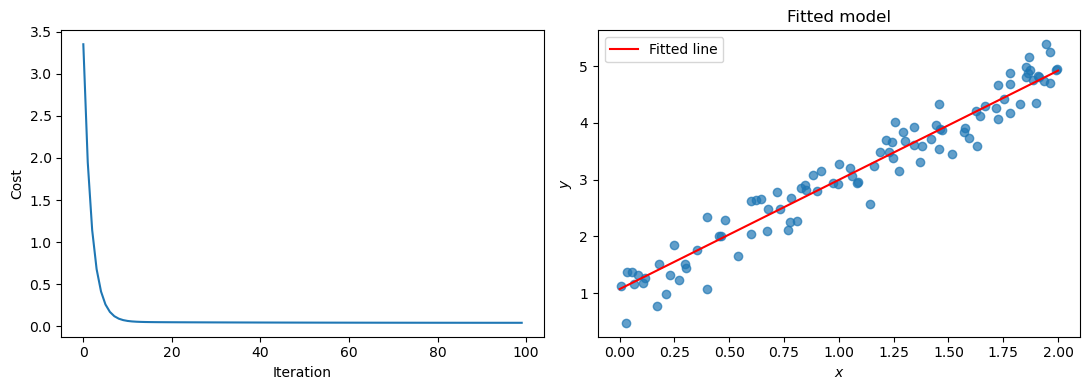

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(history)
axes[0].set_xlabel("Iteration")
axes[0].set_ylabel("Cost")

axes[1].scatter(x, y, alpha=0.7)
axes[1].plot(x_line, predict(x_line, w_fit, b_fit), color="red", label="Fitted line")
axes[1].set_xlabel("$x$")
axes[1].set_ylabel("$y$")
axes[1].set_title("Fitted model")
axes[1].legend()

plt.tight_layout()
plt.show()

### Exercise 3: The learning rate

Run gradient descent with a range of learning rates and plot all loss curves on one set of axes.
What happens when the learning rate is too small? Too large?

/tmp/ipykernel_1379/3139454072.py:19: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


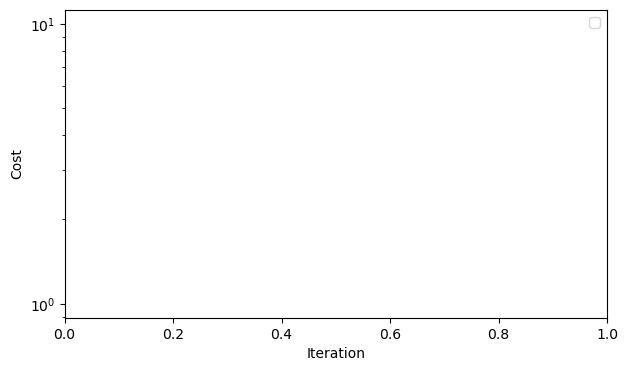

In [ ]:
# TODO: choose a range of learning rates to test
learning_rates = []

fig, ax = plt.subplots(figsize=(7, 4))

for lr in learning_rates:
    # TODO: run gradient_descent with this learning rate for 100 iterations
    for i in range(100):

    # TODO: plot the cost history with label=f"lr = {lr}"


ax.set_yscale("log")
ax.set_xlabel("Iteration")
ax.set_ylabel("Cost")
ax.legend()
plt.show()

---
## 5. Putting It Together

### Exercise 4: A linear regression class

Complete the class, then compare your result with `np.polyfit`, which solves the problem exactly.

In [ ]:
class LinearRegression1D:
    """1D linear regression trained with gradient descent."""

    def __init__(self, lr=0.1, n_iters=500):
        self.lr = lr
        self.n_iters = n_iters
        self.w = 0.0
        self.b = 0.0
        self.history = []

    def fit(self, x, y):
        for _ in range(self.n_iters):
            # TODO: compute the gradients
  
            # TODO: update self.w and self.b

            # TODO: append the current cost to self.history

    def predict(self, x):
        # TODO: return the predictions


In [ ]:
model = LinearRegression1D(lr=0.1, n_iters=500).fit(x, y)
w_exact, b_exact = np.polyfit(x, y, deg=1)

print(f"Gradient descent: w = {model.w:.4f}, b = {model.b:.4f}")
print(f"np.polyfit:       w = {w_exact:.4f}, b = {b_exact:.4f}")

# Check your answer (should print True True)
print(np.isclose(model.w, w_exact, atol=1e-3), np.isclose(model.b, b_exact, atol=1e-3))

## Technical - apply your linear regression model to data in responses_week1_real.csv

##### - is the data complete?
##### - which features will you choose?